# 🎨 Why Visualize, and Which Chart?

**Zero Grad · Data Analysis course · Visualization**

> 📖 **The lesson (in Arabic), with diagrams and interactive widgets:** [zero-grad.com/courses/da/viz](https://zero-grad.com/courses/da/viz/)
>
> 🗂️ **The data:** [NileCart Sales on Kaggle](https://www.kaggle.com/datasets/a7madmostafa/nilecart-sales)

This is the solved notebook of the first Visualization lesson. The rest of the section goes **by chart type**
(distribution, comparison, relationship, composition, change over time, multivariate), not by library.
This lesson sets that up: why draw at all, how the question picks the chart, what makes a chart clear,
and the three libraries we use, in brief.

| # | Part | The idea |
|---|---|---|
| 1 | Why draw | Summary numbers can hide the shape |
| 2 | The question picks the chart | Six questions, six chart families |
| 3 | A clear chart | Sort, start at zero, one highlight, a title that says the finding |
| 4 | Matplotlib | Figure and Axes: full control |
| 5 | Seaborn | `data=`, `x=`, `y=`, `hue=`: statistics built in |
| 6 | Plotly | Interactive, for the screen |
| 7 | Saving | PNG for slides, HTML for the web |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.0f}".format

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/nilecart/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0].parent if on_kaggle else Path("../../data/nilecart")

sales = pd.read_csv(DATA / "sales.csv", parse_dates=["order_date"])
done = sales[sales["status"] == "completed"].copy()
done["month"] = done["order_date"].dt.to_period("M").dt.to_timestamp()
print(len(done), "completed order lines")

1074 completed order lines


---
# 1️⃣ Why draw?

## 1.1 Same numbers, different data

Four small datasets, published by the statistician Francis Anscombe in 1973 to make exactly this point:

In [2]:
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = pd.DataFrame({
    "set": np.repeat(["I", "II", "III", "IV"], 11),
    "x": x * 3 + [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
    "y": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68,
          9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74,
          7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73,
          6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89],
})
summary = anscombe.groupby("set").agg(x_mean=("x", "mean"), y_mean=("y", "mean"), y_std=("y", "std"))
summary["corr"] = anscombe.groupby("set").apply(lambda g: g["x"].corr(g["y"]), include_groups=False)
summary.style.format("{:.2f}")

,x_mean,y_mean,y_std,corr
set,,,,
I,9.00,7.50,2.03,0.82
II,9.00,7.50,2.03,0.82
III,9.00,7.50,2.03,0.82
IV,9.00,7.50,2.03,0.82


Same means, same standard deviation, same correlation. By the numbers, four copies of one dataset. Now draw them:

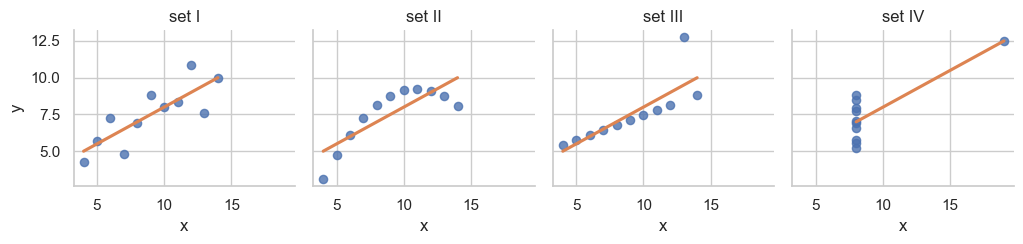

In [3]:
g = sns.lmplot(data=anscombe, x="x", y="y", col="set", col_wrap=4, height=2.6, ci=None,
               scatter_kws={"s": 35}, line_kws={"color": "C1"})
g.set_titles("set {col_name}")
plt.show()

A line, a curve, a line with one outlier, and a vertical stack with one far point. Four different stories, one summary table.

## 1.2 A table hides what a chart shows

NileCart's revenue per month, as a table:

In [4]:
monthly = done.groupby("month")["revenue"].sum()
table = monthly.to_frame("revenue").assign(year=lambda d: d.index.year, m=lambda d: d.index.strftime("%b"))
table.pivot(index="year", columns="m", values="revenue")[["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                                         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]] / 1000

m,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2024,547,427,545,341,631,481,789,517,"1,119",982,"1,285","2,075"
2025,821,621,806,381,586,610,434,620,662,743,"1,763","1,625"


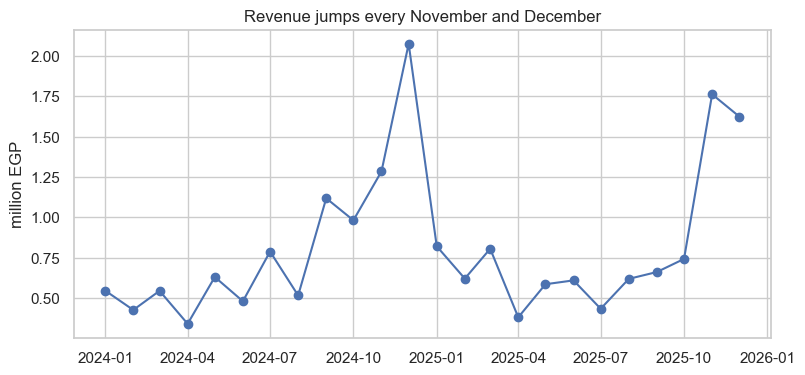

In [5]:
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly / 1e6, marker="o")
ax.set(title="Revenue jumps every November and December", ylabel="million EGP", xlabel="")
plt.show()

The table has every number; the chart shows the pattern in a second: two peaks, one per year, at the end of the year.
**Tables are for looking up a value. Charts are for seeing a pattern.**

---
# 2️⃣ The question picks the chart

Start from the question, not from the chart type. Almost every question about a table falls into one of six families,
and each family has its own charts (and its own lesson in this course):

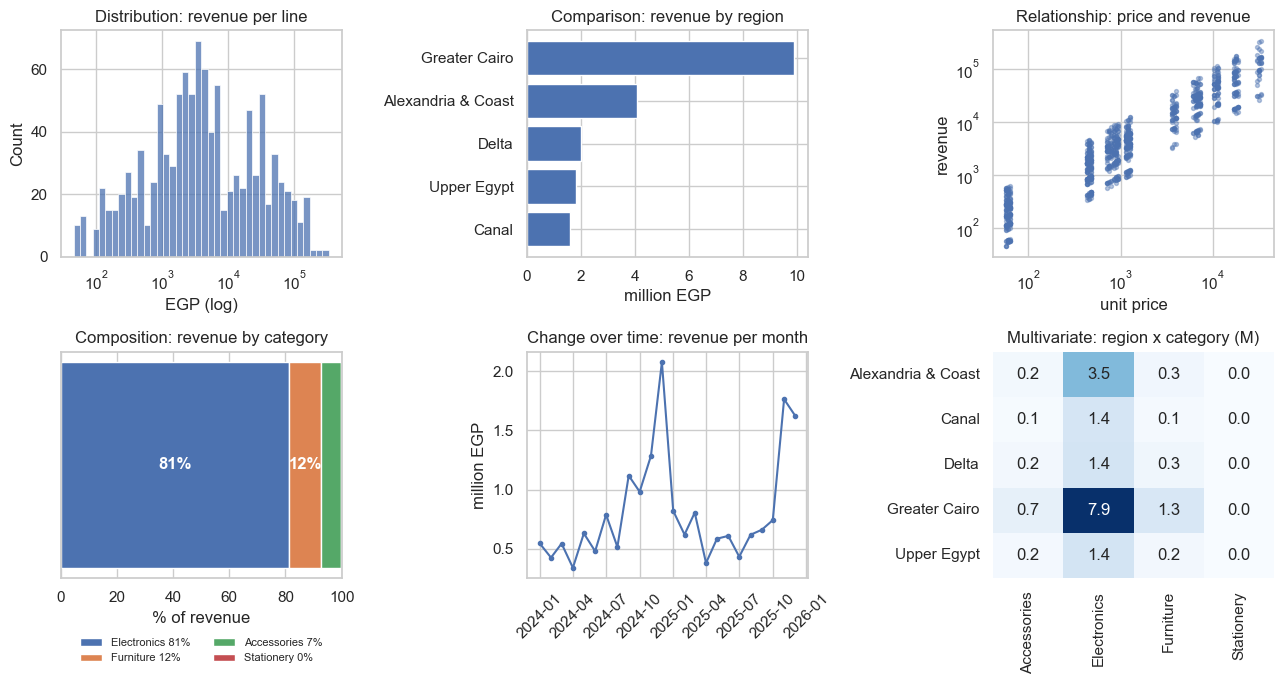

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

# distribution: what do the values look like?
sns.histplot(done["revenue"], bins=40, log_scale=True, ax=axes[0, 0])
axes[0, 0].set(title="Distribution: revenue per line", xlabel="EGP (log)")

# comparison: which is bigger?
reg = done.groupby("region")["revenue"].sum().drop("Unknown").sort_values() / 1e6
axes[0, 1].barh(reg.index, reg.values, color="C0")
axes[0, 1].set(title="Comparison: revenue by region", xlabel="million EGP")

# relationship: do two numbers move together?
axes[0, 2].scatter(done["unit_price"], done["revenue"], s=8, alpha=.4)
axes[0, 2].set(xscale="log", yscale="log", title="Relationship: price and revenue", xlabel="unit price", ylabel="revenue")

# composition: what is the whole made of?
share = done.groupby("category")["revenue"].sum().sort_values(ascending=False)
share = share / share.sum() * 100
left = 0
for i, (k, v) in enumerate(share.items()):
    axes[1, 0].barh([0], [v], left=left, color=f"C{i}", label=f"{k} {v:.0f}%")
    if v > 10:
        axes[1, 0].text(left + v / 2, 0, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += v
axes[1, 0].set(title="Composition: revenue by category", xlabel="% of revenue", yticks=[], xlim=(0, 100))
axes[1, 0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)

# change over time: how does it move?
axes[1, 1].plot(monthly.index, monthly / 1e6, marker=".")
axes[1, 1].set(title="Change over time: revenue per month", ylabel="million EGP")
axes[1, 1].tick_params(axis="x", rotation=45)

# multivariate: several variables at once
pv = done.pivot_table(index="region", columns="category", values="revenue", aggfunc="sum").drop(index="Unknown") / 1e6
sns.heatmap(pv, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=axes[1, 2])
axes[1, 2].set(title="Multivariate: region x category (M)", xlabel="", ylabel="")

plt.tight_layout()
plt.show()

| Question | Family | Typical charts | Lesson |
|---|---|---|---|
| What do the values look like? | Distribution | histogram, box, violin, ECDF | Distribution |
| Which is bigger? Who's first? | Comparison & ranking | sorted bar, dot plot | Comparison & ranking |
| Do two numbers move together? | Relationship | scatter, heatmap of correlations | Relationship & correlation |
| What is the whole made of? | Composition | stacked bar, treemap (pie only for 2–3 parts) | Composition |
| How does it change over time? | Change over time | line, area | Change over time |
| Several variables at once? | Multivariate | heatmap, small multiples, maps | Multivariate & maps |

One question, one chart. A chart that tries to answer three questions answers none.

---
# 3️⃣ A clear chart

The same data, revenue by region, drawn badly and then fixed one rule at a time.

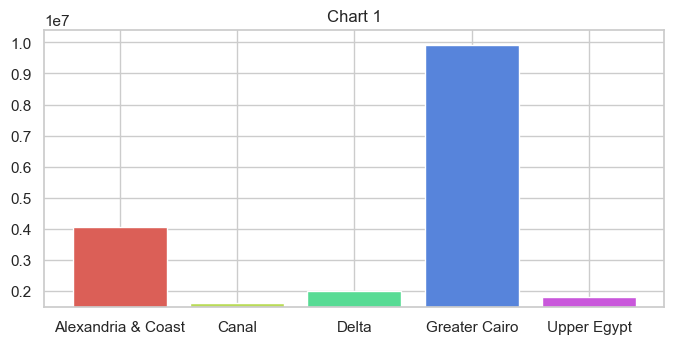

In [7]:
reg = done.groupby("region")["revenue"].sum().drop("Unknown")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(reg.index, reg.values, color=sns.color_palette("hls", len(reg)))
ax.set_ylim(1.5e6, None)
ax.set_title("Chart 1")
plt.show()

What's wrong:

* **The axis starts at 1.5M**, so Canal's bar is almost nothing: Greater Cairo looks 75 times bigger instead of 6.
* **Alphabetical order**: you have to search for the biggest and the smallest.
* **Rainbow colours** that mean nothing: the eye looks for a meaning that isn't there.
* **No units, a title that says nothing**, and `1e7` in the corner.

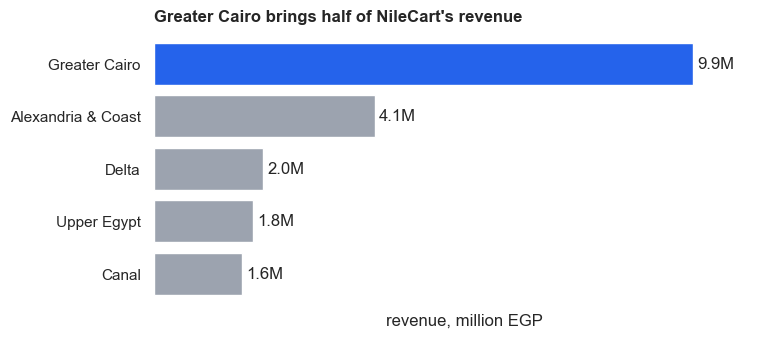

In [8]:
reg = reg.sort_values() / 1e6                                   # sort, and use readable units
colors = ["#9ca3af"] * len(reg)
colors[-1] = "#2563eb"                                          # one highlight: the point of the chart

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(reg.index, reg.values, color=colors)            # horizontal: long labels read easily
ax.bar_label(bars, fmt="%.1fM", padding=3)                      # label the bars, drop the grid
ax.set_xlim(0, reg.max() * 1.15)                                # bars start at zero
ax.set(xlabel="revenue, million EGP", ylabel="")
ax.set_title("Greater Cairo brings half of NileCart's revenue", loc="left", fontweight="bold")
ax.grid(False)
sns.despine(left=True, bottom=True)
ax.set_xticks([])
plt.show()

In [9]:
print(f"Greater Cairo share: {reg['Greater Cairo'] / reg.sum():.0%}")

Greater Cairo share: 51%


| Rule | Why |
|---|---|
| Bars start at **zero** | a bar's length *is* its value; cut the axis and you lie about the ratio |
| **Sort** by value | the ranking is visible without reading |
| **One** highlight colour, grey for the rest | colour means something, so use it once, for the point |
| A **title that says the finding** | "Greater Cairo brings half" beats "Revenue by region" |
| **Units** in the label, readable numbers | 9.9M, not 9912413.2 or 1e7 |
| Label directly, remove what doesn't help | gridlines, legends and borders are ink that says nothing |

(A line chart is different: it shows change, so its axis doesn't have to start at zero.)

---
# 4️⃣ Matplotlib: full control

Matplotlib is the base of Python plotting; Seaborn and Pandas' `.plot()` draw with it.
Its model: a **Figure** (the canvas) holds one or more **Axes** (each a chart with its own x and y axis).

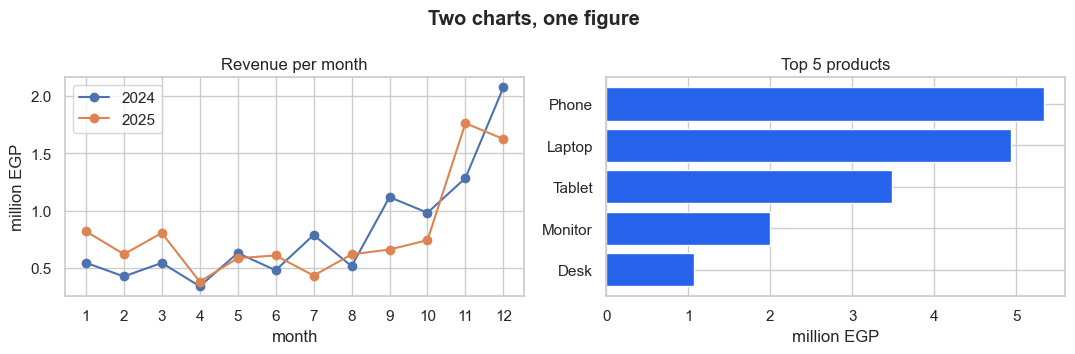

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))          # one figure, two axes

by_year = done.groupby([done["order_date"].dt.year, done["order_date"].dt.month])["revenue"].sum().unstack(0) / 1e6
for year in by_year.columns:
    axes[0].plot(by_year.index, by_year[year], marker="o", label=year)
axes[0].set(title="Revenue per month", xlabel="month", ylabel="million EGP", xticks=range(1, 13))
axes[0].legend()

top = done.groupby("product_name")["revenue"].sum().nlargest(5).sort_values() / 1e6
axes[1].barh(top.index, top.values, color="#2563eb")
axes[1].set(title="Top 5 products", xlabel="million EGP")

fig.suptitle("Two charts, one figure", fontweight="bold")
plt.tight_layout()
plt.show()

Everything is a method on the Axes: `ax.plot`, `ax.bar`, `ax.scatter`, `ax.hist`, then `ax.set(title=..., xlabel=..., ylabel=...)`.
You can change any detail, which is why it takes more lines.

Pandas has a shortcut that calls Matplotlib for you:

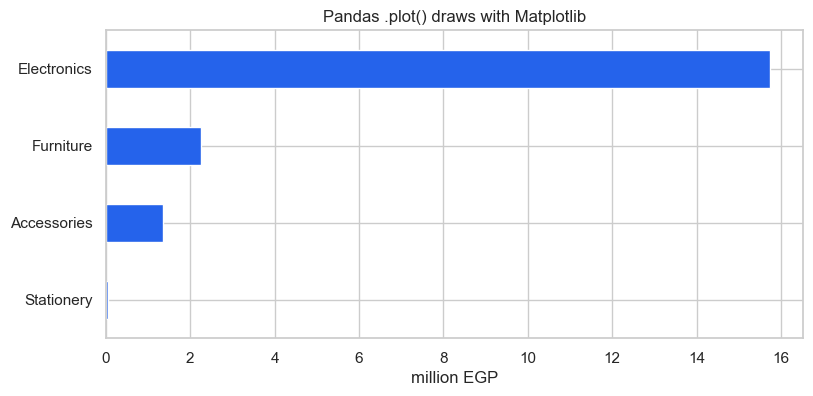

In [11]:
ax = (done.groupby("category")["revenue"].sum().sort_values() / 1e6).plot(kind="barh", color="#2563eb")
ax.set(xlabel="million EGP", ylabel="", title="Pandas .plot() draws with Matplotlib")
plt.show()

---
# 5️⃣ Seaborn: statistics built in

Seaborn takes a DataFrame and column names: `data=`, `x=`, `y=`, `hue=`. It groups and aggregates for you.

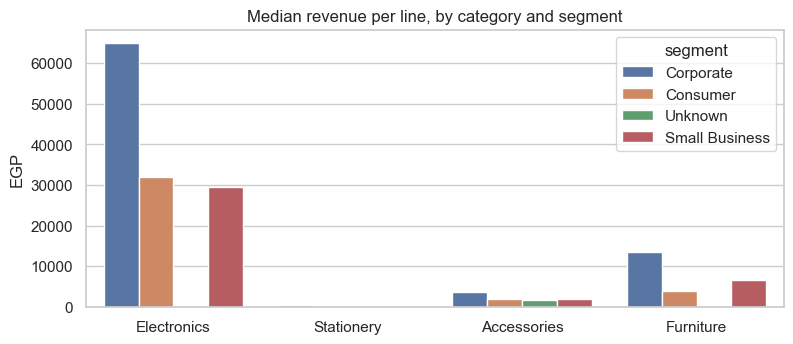

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.barplot(data=done, x="category", y="revenue", hue="segment", estimator="median", errorbar=None, ax=ax)
ax.set(title="Median revenue per line, by category and segment", xlabel="", ylabel="EGP")
plt.show()

One line: grouped by category **and** segment, the median of each group, colour by segment, a legend.
In Matplotlib that's a `groupby`, a loop and manual offsets.

⚠️ `sns.barplot` aggregates: the default estimator is the **mean**, and by default it draws an error bar (a confidence interval).
Know which number your bar is.

Seaborn also has figure-level functions that make one small chart per group (*small multiples*):

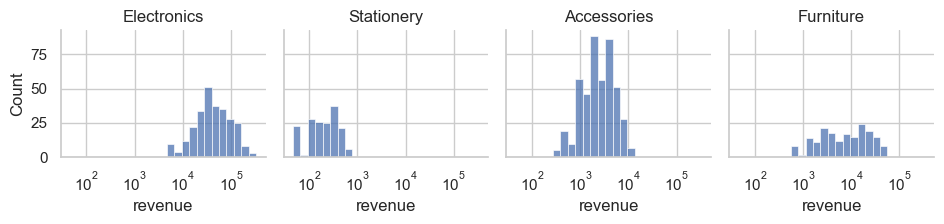

In [13]:
g = sns.displot(data=done, x="revenue", col="category", col_wrap=4, log_scale=True, height=2.4, bins=25)
g.set_titles("{col_name}")
plt.show()

---
# 6️⃣ Plotly: interactive, for the screen

Plotly Express has the same idea as Seaborn (a DataFrame and column names), but the chart is a web page:
hover for the exact value, zoom, click the legend to hide a series.

In [14]:
m = done.groupby(["month", "category"], as_index=False)["revenue"].sum()
fig = px.line(m, x="month", y="revenue", color="category", markers=True,
              title="Revenue per month, by category (hover, zoom, click the legend)")
fig.update_layout(height=380, yaxis_title="EGP", xaxis_title="")
fig.show()

⚠️ Unlike Seaborn, `px.bar` does **not** aggregate: it draws one bar segment per row. Group first:

In [15]:
reg = done.groupby("region", as_index=False)["revenue"].sum().sort_values("revenue")
fig = px.bar(reg, x="revenue", y="region", orientation="h", text_auto=".3s", title="Group first, then px.bar")
fig.update_layout(height=320, xaxis_title="EGP", yaxis_title="")
fig.show()

## 6.1 Which one?

| | Matplotlib | Seaborn | Plotly |
|---|---|---|---|
| Style | every detail by hand | statistical charts from a DataFrame | interactive charts from a DataFrame |
| Aggregates for you | no | yes (`estimator=`) | histogram/box yes, bar no |
| Output | image | image (drawn by Matplotlib) | web page |
| Best for | a final chart for a report, full control | exploring fast, statistics, small multiples | dashboards, sharing on the web, hover |

This course shows each chart in all three. Pick one for exploring (Seaborn is quickest), and know the others exist.

---
# 7️⃣ Saving

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(monthly.index, monthly / 1e6, marker="o")
ax.set(title="Revenue per month", ylabel="million EGP")
fig.savefig("revenue.png", dpi=150, bbox_inches="tight")      # bbox_inches: don't cut the labels
plt.close(fig)

fig = px.line(monthly.reset_index(), x="month", y="revenue")
fig.write_html("revenue.html", include_plotlyjs="cdn")         # a page anyone can open

for f in ["revenue.png", "revenue.html"]:
    print(f, f"{Path(f).stat().st_size / 1024:.0f} KB")
    Path(f).unlink()                                            # tidy up

revenue.png 47 KB
revenue.html 9 KB


---
# 🧰 Summary

* **Draw before you summarise**: the same summary numbers can come from very different data.
* **Tables to look up, charts to see a pattern.**
* **Start from the question**: distribution, comparison, relationship, composition, change over time, multivariate.
* **A clear chart**: zero baseline for bars, sorted, one highlight, a title with the finding, units, nothing extra.
* **Three libraries**: Matplotlib (`fig, ax = plt.subplots()`), Seaborn (`data=, x=, y=, hue=`), Plotly (`px.*`, interactive).

| Task | Matplotlib | Seaborn | Plotly |
|---|---|---|---|
| Start | `fig, ax = plt.subplots()` | `sns.set_theme()` | `import plotly.express as px` |
| Line | `ax.plot(x, y)` | `sns.lineplot(data=, x=, y=)` | `px.line(df, x=, y=)` |
| Bar | `ax.bar(x, h)` / `ax.barh` | `sns.barplot(data=, x=, y=)` (aggregates) | `px.bar(df, x=, y=)` (doesn't) |
| Labels | `ax.set(title=, xlabel=, ylabel=)` | same (it's Matplotlib) | `fig.update_layout(title=, ...)` |
| Save | `fig.savefig("f.png", dpi=150, bbox_inches="tight")` | same | `fig.write_html("f.html")` |

**Next lesson:** Distribution: what do my numbers look like?

📚 All the lessons of the course: [zero-grad.com/courses/da](https://zero-grad.com/courses/da/)